[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C1_NB02_qif_theta_rotator.ipynb)

# Day 1 · Chapter 1 · Notebook 02 — One variable is enough: QIF, theta neuron, active rotator

**Goal.** Throw away almost everything in Hodgkin–Huxley and keep only the *onset of the spike*.
We get a one-variable neuron that still has a threshold, spikes and repetitive firing, and that we
can solve with pen and paper. We then see that three famous models are the **same unit written in
different variables**:

$$
\text{QIF } (v) \;\;\Longleftrightarrow\;\; \text{theta neuron } (\theta) \;\;\Longleftrightarrow\;\; \text{active rotator } (\varphi)
$$

This unit is the building block for the rest of Day 1: networks (Chapter 2) and exact mean fields (Chapter 3).

| detailed morphology | Hodgkin–Huxley | 2D reductions | **QIF / LIF** | **phase models** |
|---|---|---|---|---|
| thousands of variables | 4 variables | 2 variables | **1 variable** | **1 angle** |

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import neurons

## 0. Why a quadratic? From a 2D neuron to the QIF

Before throwing everything away, let us see *why* the simple equation $\dot v = v^2 + I$ is a good
description of real neurons near threshold. We use a two-variable conductance model, the
**persistent-sodium + potassium** model (Izhikevich 2007), which is HH with only one fast Na⁺ gate and one K⁺ gate:

$$
C\frac{dV}{dt} = I - g_L(V-E_L) - g_\text{Na}\,m_\infty(V)\,(V-E_\text{Na}) - g_\text{K}\,n\,(V-E_\text{K}),
\qquad
\frac{dn}{dt} = \frac{n_\infty(V)-n}{\tau_n}
$$

With two variables we can draw the whole state of the neuron in a plane $(V, n)$ and use **nullclines**:
* the **V-nullcline** ($dV/dt=0$) is **N-shaped** (cubic-like): it has a left "knee";
* the **n-nullcline** ($dn/dt=0$) is the sigmoid $n=n_\infty(V)$;
* where they cross, nothing moves: these are the **fixed points**.

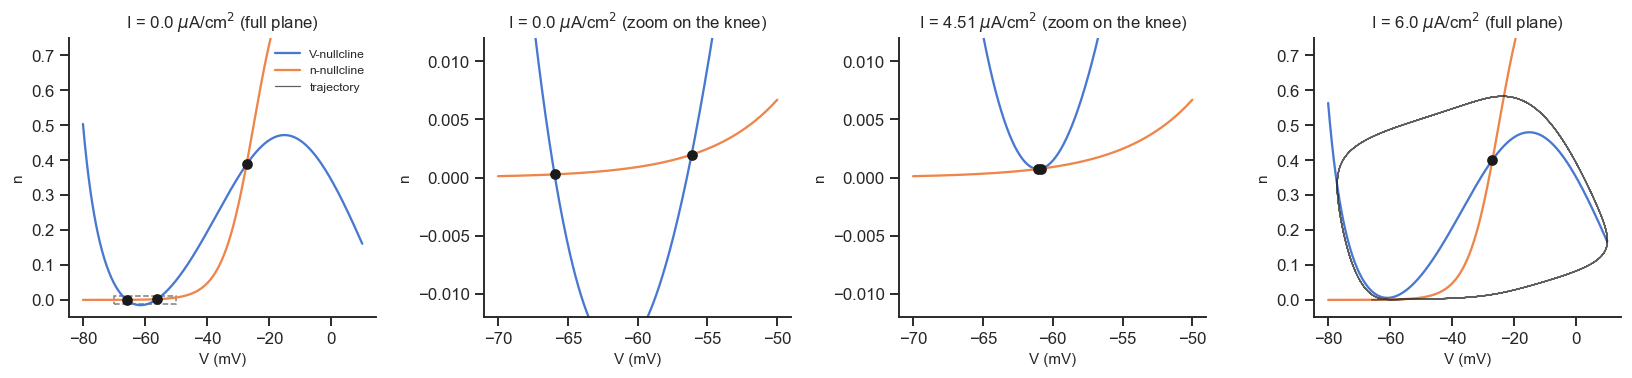

In [2]:
V = np.linspace(-80, 10, 600)
Vz = np.linspace(-70, -50, 400)                       # zoom window around the knee
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
panels = [(ax[0], 0.0, V, (-0.05, 0.75), "full plane"), (ax[1], 0.0, Vz, (-0.012, 0.012), "zoom on the knee"),
          (ax[2], 4.51, Vz, (-0.012, 0.012), "zoom on the knee"), (ax[3], 6.0, V, (-0.05, 0.75), "full plane")]
for a_, I0, VV, ylim, what in panels:
    nV, nn = neurons.inapk_nullclines(VV, I0)
    a_.plot(VV, nV, "C0", label="V-nullcline"); a_.plot(VV, nn, "C1", label="n-nullcline")
    if what == "full plane":
        Vt, n_t = neurons.inapk(np.full(int(60 / 0.01), I0), 0.01, V0=-66.0, n0=0.0)
        a_.plot(Vt, n_t, "k", lw=0.8, alpha=0.7, label="trajectory")
    for Vf, nf in neurons.inapk_fixed_points(I0):
        if VV[0] <= Vf <= VV[-1]:
            a_.plot(Vf, nf, "o", c="k", ms=6, zorder=5)
    a_.set(xlabel="V (mV)", ylabel="n", ylim=ylim, title=fr"I = {I0} $\mu$A/cm$^2$ ({what})")
ax[0].add_patch(plt.Rectangle((-70, -0.012), 20, 0.024, fill=False, ec="gray", ls="--"))
ax[0].legend(fontsize=8)
plt.tight_layout()

* $I=0$ (first two panels): the nullclines cross three times. Near the knee (zoom, dashed box) there are
  two crossings: the stable **rest** (left) and a **saddle** (right), which acts as the threshold. The third
  crossing, high up, is unstable. The trajectory goes to rest.
* $I\approx 4.51$ (third panel): the V-nullcline has moved up, and rest and saddle **merge** at the knee:
  a **saddle-node bifurcation**. Just above this value they are gone.
* $I=6$: no fixed point is left near the knee: the trajectory runs around a closed loop forever (repetitive firing).

**Where the quadratic comes from.** Fixed points satisfy $I = I_\text{ss}(V)$, where $I_\text{ss}(V)$ is the
steady-state current–voltage curve (the current needed to hold the neuron at voltage $V$).
At the knee $I_\text{ss}$ has a maximum, and *any* smooth function looks like a parabola near its maximum:

$$
I_\text{ss}(V)\approx I_\text{SN} - c\,(V-V_\text{SN})^2
\quad\Longrightarrow\quad
\frac{dV}{dt}\;\propto\; I - I_\text{ss}(V) \;\approx\; (I-I_\text{SN}) + c\,(V-V_\text{SN})^2 .
$$

After rescaling, this is exactly $\dot v = v^2 + I$: the **QIF is the normal form of the saddle-node
bifurcation**. Every neuron that starts firing through a saddle-node behaves like a QIF near threshold,
whatever its ion channels.

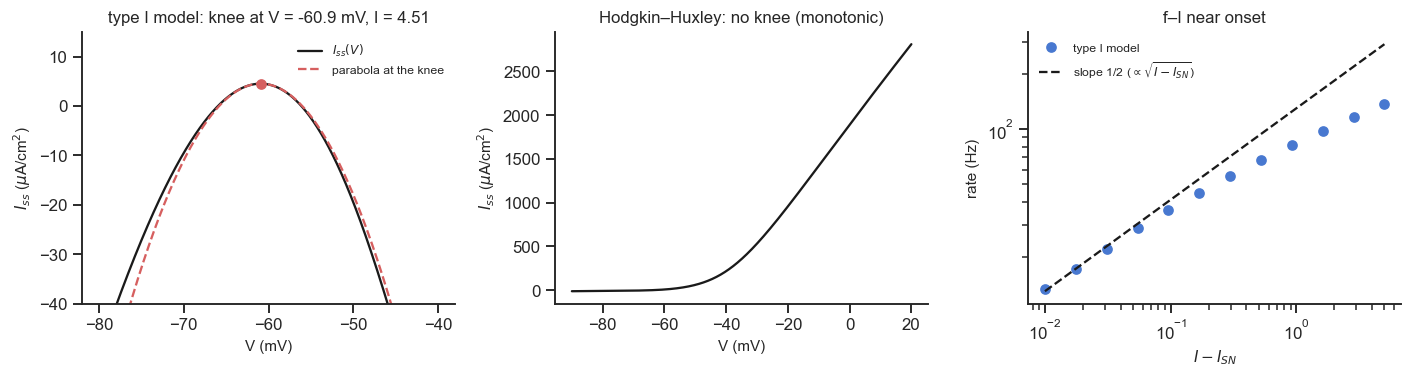

In [3]:
V = np.linspace(-80, -40, 800)
Iss = neurons.inapk_steady_current(V)
k = np.argmax(np.where(V < -50, Iss, -np.inf))            # the knee: local maximum of I_ss
V_SN, I_SN = V[k], Iss[k]
c = -np.gradient(np.gradient(Iss, V), V)[k] / 2            # curvature at the knee
Vh = np.linspace(-90, 20, 800)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(V, Iss, "k", label=r"$I_{ss}(V)$")
ax[0].plot(V, I_SN - c * (V - V_SN) ** 2, "C3--", label="parabola at the knee")
ax[0].plot(V_SN, I_SN, "o", c="C3")
ax[0].set(xlabel="V (mV)", ylabel=r"$I_{ss}$ ($\mu$A/cm$^2$)", ylim=(-40, 15),
          title=f"type I model: knee at V = {V_SN:.1f} mV, I = {I_SN:.2f}")
ax[0].legend(fontsize=8)

ax[1].plot(Vh, neurons.hh_steady_current(Vh), "k")
ax[1].set(xlabel="V (mV)", ylabel=r"$I_{ss}$ ($\mu$A/cm$^2$)", title="Hodgkin–Huxley: no knee (monotonic)")

dI = np.logspace(-2, 0.7, 12)
rates = []
for d in dI:
    Vt, _ = neurons.inapk(np.full(int(2000 / 0.01), I_SN + d), 0.01, V0=-62.0)
    st = neurons.spike_times(Vt, 0.01, threshold=-20.0); st = st[st > 200]
    rates.append(1000 * len(st) / 1800)
ax[2].loglog(dI, rates, "o", label="type I model")
ax[2].loglog(dI, 130 * np.sqrt(dI), "k--", label=r"slope 1/2 ($\propto\sqrt{I-I_{SN}}$)")
ax[2].set(xlabel=r"$I - I_{SN}$", ylabel="rate (Hz)", title="f–I near onset")
ax[2].legend(fontsize=8)
plt.tight_layout()

* Left: near the knee, the I–V curve of the 2D model *is* a parabola. This is the quadratic of the QIF.
* Middle: Hodgkin–Huxley has no knee. Its rest state does not disappear through a saddle-node but loses
  stability through a **Hopf** bifurcation (NB01). So the QIF is a faithful reduction of **type I** neurons
  (most cortical excitatory cells) and only a rougher caricature of type II neurons like the squid axon.
* Right: close to onset the firing rate grows like $\sqrt{I-I_\text{SN}}$, as the QIF predicts ($f=\sqrt I/\pi$, section 3).
  Far from onset the spike shape matters and the law bends.

### Explore: the nullclines move with the input

* Increase $I$ slowly from 0 and watch the number of fixed points in the title: when does it drop from 3 to 1?
* Just above $I_\text{SN}\approx 4.51$, how long does the neuron take between spikes? Where does it spend that time?

In [4]:
@interact(I0=slider(2.0, -5.0, 15.0, 0.05, "input I (uA/cm²)"))
def explore_nullclines(I0):
    V = np.linspace(-80, 10, 600)
    nV, nn = neurons.inapk_nullclines(V, I0)
    t = np.arange(0, 100, 0.01)
    Vt, n_t = neurons.inapk(np.full(t.size, I0), 0.01, V0=-66.0, n0=0.0)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1, 1.5]))
    ax[0].plot(V, nV, "C0", label="V-nullcline"); ax[0].plot(V, nn, "C1", label="n-nullcline")
    ax[0].plot(Vt, n_t, "k", lw=0.8, alpha=0.7)
    for Vf, nf in neurons.inapk_fixed_points(I0):
        ax[0].plot(Vf, nf, "o", c="k", ms=6, zorder=5)
    ax[0].set(xlabel="V (mV)", ylabel="n", ylim=(-0.05, 0.75),
              title=f"I = {I0:.2f}: {len(neurons.inapk_fixed_points(I0))} fixed point(s)"); ax[0].legend(fontsize=8)
    ax[1].plot(t, Vt, "k", lw=0.8)
    nsp = len(neurons.spike_times(Vt, 0.01, threshold=-20.0))
    ax[1].set(xlabel="time (ms)", ylabel="V (mV)", ylim=(-80, 15), title=f"{nsp} spikes in 100 ms")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='input I (uA/cm²)', layout=L…

## 1. The quadratic integrate-and-fire (QIF) neuron

Close to the onset of a spike, the voltage of many neurons obeys, after rescaling time and voltage,

$$
\frac{dv}{dt} = v^2 + I
$$

* $v$: membrane potential (dimensionless). $I$: input current (dimensionless).
* Time is in units of the membrane time constant ($\tau_m \approx 10$ ms, so $t=1$ means ~10 ms).
* The $v^2$ term is the fast positive feedback of the Na⁺ current: the higher $v$, the faster it grows.
  In finite time $v$ reaches $+\infty$: that is the spike.
* After the spike, $v$ is reset to $-\infty$ (in practice: when $v$ reaches $v_\text{peak}=100$ we reset it to $-100$).

**Read the dynamics from a single plot (the phase line).** Plot $dv/dt$ against $v$. Where the curve is
above zero, $v$ increases; below zero, it decreases; where it crosses zero, $v$ stays put (a fixed point).

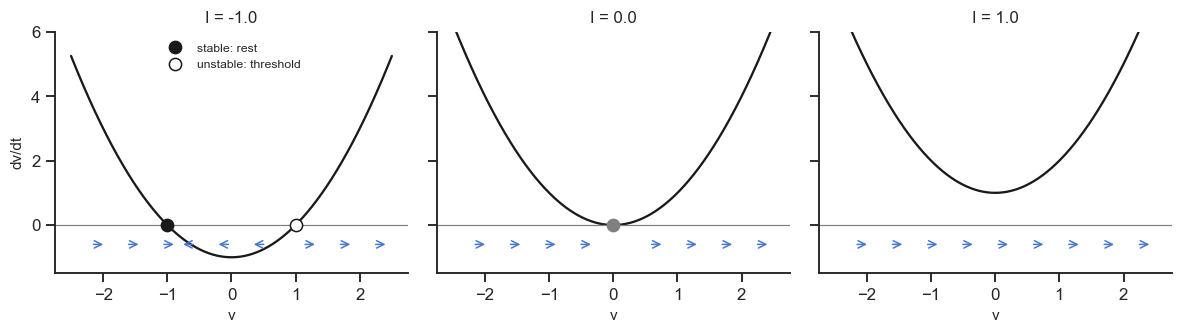

In [5]:
v = np.linspace(-2.5, 2.5, 400)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for a_, I in zip(ax, [-1.0, 0.0, 1.0]):
    a_.plot(v, v**2 + I, "k")
    a_.axhline(0, c="gray", lw=0.8)
    if I < 0:
        a_.plot(-np.sqrt(-I), 0, "o", c="k", ms=8, label="stable: rest")
        a_.plot(np.sqrt(-I), 0, "o", mfc="white", c="k", ms=8, label="unstable: threshold")
        a_.legend(fontsize=8, loc="upper center")
    elif I == 0:
        a_.plot(0, 0, "o", c="gray", ms=8)
    # arrows showing the flow on the line
    for x0 in np.linspace(-2.2, 2.2, 9):
        d = np.sign(x0**2 + I)
        if d != 0:
            a_.annotate("", xy=(x0 + 0.25 * d, -0.6), xytext=(x0, -0.6),
                        arrowprops=dict(arrowstyle="->", color="C0"))
    a_.set(title=f"I = {I}", xlabel="v", ylim=(-1.5, 6))
ax[0].set_ylabel("dv/dt")
plt.tight_layout()

* $I<0$: two fixed points. $v_\text{rest}=-\sqrt{-I}$ is **stable** (the resting potential);
  $v_\text{th}=+\sqrt{-I}$ is **unstable**: it is the **threshold**. Start below it and you return to
  rest; start above it and $v$ runs away to $+\infty$: a spike.
* $I=0$: the two fixed points merge.
* $I>0$: no fixed points left. $v$ always increases, reaches $+\infty$, is reset, and starts again:
  **repetitive firing**.

The disappearance of two fixed points when they collide is a **saddle-node bifurcation**.
Everything this neuron can do is read from this one picture.

### Explore: move the input, watch the fixed points

Left: the phase line for your value of $I$. Right: $v(t)$ starting from $v_0$ (the red dot on the left).
* Start from $I=-1$, $v_0=0$: where does $v$ go? Now $v_0=1.2$?
* Bring $I$ toward 0. What happens to the distance between rest and threshold? And to the time $v$ spends near $v=0$?
* Cross to $I>0$: how does the time between spikes change as you increase $I$?

In [6]:
dt = 0.001   
@interact(I=slider(-1.0, -2.0, 2.0, 0.05, "input I"), v0=slider(0.0, -3.0, 3.0, 0.1, "initial v0"))
def explore_phase_line(I, v0):
    v = np.linspace(-3, 3, 400)
    t = np.arange(0, 15, dt)
    vv, spk = neurons.qif(np.full(t.size, I), dt, v0=v0)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
    ax[0].plot(v, v**2 + I, "k"); ax[0].axhline(0, c="gray", lw=0.8)
    if I < 0:
        ax[0].plot(-np.sqrt(-I), 0, "o", c="k", ms=8); ax[0].plot(np.sqrt(-I), 0, "o", mfc="white", c="k", ms=8)
    ax[0].plot(v0, v0**2 + I, "o", c="C3", ms=8)
    ax[0].set(xlabel="v", ylabel="dv/dt", ylim=(-2.5, 6), title=f"I = {I:.2f}")
    ax[1].plot(t, np.clip(vv, -4, 4), "C3")
    ax[1].set(xlabel="time", ylabel="v (clipped)", ylim=(-4.2, 4.2),
              title=f"{len(spk)} spikes" + (f", period {np.diff(spk).mean():.2f} (theory {np.pi/np.sqrt(I):.2f})" if len(spk) > 1 else ""))
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=-1.0, continuous_update=False, description='input I', layout=Layout(wi…

## 2. Perturbation: pulses and the threshold

The QIF sits at rest ($I=-1$, $v=-1$). A short pulse moves $v$ up. If it crosses the threshold ($v=+1$)
the neuron spikes.

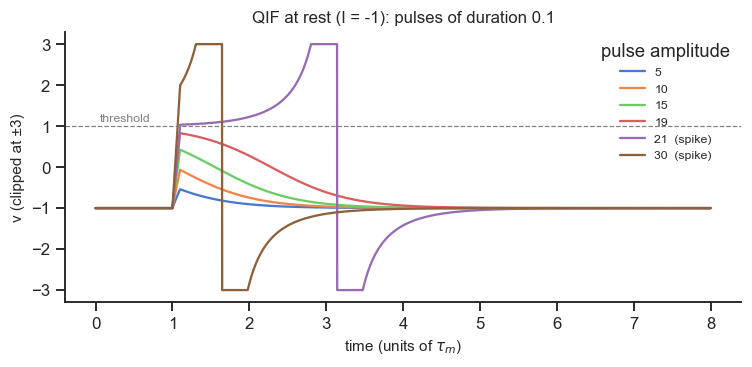

In [8]:
dt = 1e-3
t = np.arange(0, 8, dt)
fig, ax = plt.subplots(figsize=(7, 3.5))
for amp in [5, 10, 15, 19, 21, 30]:
    I = -1.0 + np.where((t >= 1) & (t < 1.1), amp, 0.0)    # pulse of duration 0.1
    vv, spk = neurons.qif(I, dt, v0=-1.0)
    ax.plot(t, np.clip(vv, -3, 3), label=f"{amp}" + ("  (spike)" if len(spk) else ""))
ax.axhline(1, ls="--", c="gray", lw=0.8); ax.text(0.05, 1.1, "threshold", fontsize=8, color="gray")
ax.set(xlabel="time (units of $\\tau_m$)", ylabel="v (clipped at ±3)", title="QIF at rest (I = -1): pulses of duration 0.1")
ax.legend(title="pulse amplitude", fontsize=8)
plt.tight_layout()

Same story as Hodgkin–Huxley: graded subthreshold responses, then an all-or-none spike.
But now we *know* where the threshold is ($v_\text{th}=\sqrt{-I}$) and why it exists (an unstable fixed point).
Note the slow approach just below threshold: the neuron "hesitates" before deciding.

### Explore: threshold depends on the input

* With $I=-1$ find the smallest pulse that makes a spike. Now set $I=-0.25$: is it easier or harder?
* Keep the pulse just below threshold and make it longer. What happens?

In [9]:
@interact(I=slider(-1.0, -2.0, -0.05, 0.05, "background input I"),
          amp=slider(15.0, 0.0, 40.0, 0.5, "pulse amplitude"),
          dur=slider(0.1, 0.02, 0.5, 0.02, "pulse duration"))
def explore_qif_pulse(I, amp, dur):
    t = np.arange(0, 8, dt)
    Iext = I + np.where((t >= 1) & (t < 1 + dur), amp, 0.0)
    vv, spk = neurons.qif(Iext, dt, v0=-np.sqrt(-I))
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(t, np.clip(vv, -3, 3), "k")
    ax.axhline(np.sqrt(-I), ls="--", c="gray", lw=0.8); ax.text(7.9, np.sqrt(-I) + 0.1, "threshold", ha="right", fontsize=8, color="gray")
    ax.set(xlabel="time", ylabel="v (clipped)", ylim=(-3.2, 3.2), title="spike!" if len(spk) else "no spike")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=-1.0, continuous_update=False, description='background input I', layou…

## 3. Repetitive firing and the f–I curve

For $I>0$ the time to go from $-\infty$ to $+\infty$ is

$$
T = \int_{-\infty}^{+\infty}\frac{dv}{v^2+I} = \frac{\pi}{\sqrt I}
\qquad\Longrightarrow\qquad
f = \frac{1}{T} = \frac{\sqrt I}{\pi}
$$

So the rate goes to **zero continuously** as $I\to 0$: the QIF can fire arbitrarily slowly.
Compare with Hodgkin–Huxley, which jumps to ~55 Hz.

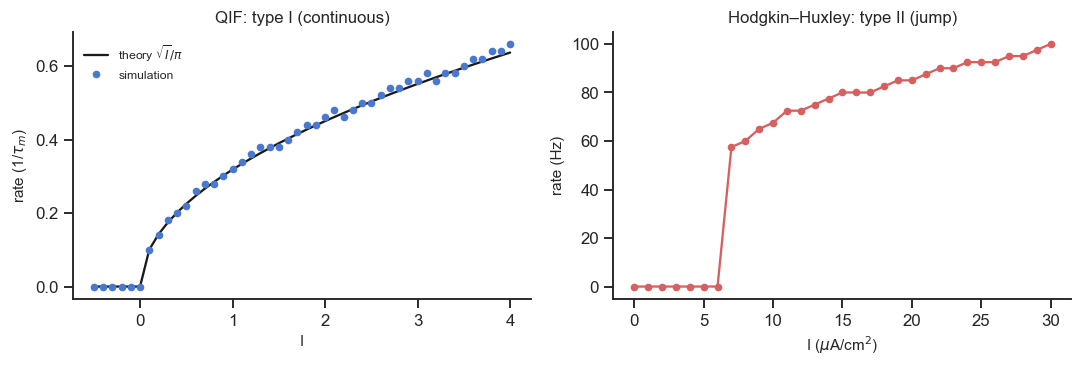

In [10]:
Is = np.linspace(-0.5, 4, 46)
f_sim = []
for I0 in Is:
    vv, spk = neurons.qif(np.full(int(60 / dt), I0), dt)
    spk = spk[spk > 10]
    f_sim.append(len(spk) / 50 if len(spk) else 0.0)

hh_I = np.linspace(0, 30, 31)
hh_f = neurons.hh_fi_curve(hh_I)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(Is, neurons.qif_rate(Is), "k", label=r"theory $\sqrt{I}/\pi$")
ax[0].plot(Is, f_sim, "o", ms=4, label="simulation")
ax[0].set(xlabel="I", ylabel="rate (1/$\\tau_m$)", title="QIF: type I (continuous)")
ax[0].legend(fontsize=8)
ax[1].plot(hh_I, hh_f, "o-", ms=4, c="C3")
ax[1].set(xlabel=r"I ($\mu$A/cm$^2$)", ylabel="rate (Hz)", title="Hodgkin–Huxley: type II (jump)")
plt.tight_layout()

This is Hodgkin's (1948) classification of excitability:

| | type I (QIF, many cortical pyramidal cells) | type II (HH squid axon, some interneurons) |
|---|---|---|
| f–I curve | starts at 0, continuous | jumps to a finite rate |
| bifurcation at onset | saddle-node (on an invariant circle, **SNIC**) | **Hopf** |
| below threshold | no ringing | damped oscillations |

**Two everyday pictures.**
* **Type I = a dripping tap.** Open the tap a tiny bit: a drop grows slowly and falls only after a long wait. Open it a
  bit more and the drops come faster. The drip rate starts from **zero** and grows smoothly. Near threshold the drop
  "hangs" for a long time; the QIF does the same near the point where its two fixed points have just merged (the
  *ghost* of the fixed points, section 5).
* **Type II = a swing (NB01).** It has its own rhythm: below threshold it wobbles back to rest, above threshold it swings
  at about the same frequency from the start. It cannot swing slowly.

Both are *excitable*: a drop hanging at the tap, or a swing at rest, can be set off by a single kick. The difference is how
they start firing **repetitively** when the input grows.

Two neurons that both "spike" can belong to different *dynamical* classes. The class, not the
molecular detail, decides how they respond to inputs and how they synchronise in networks.

## 4. Getting rid of infinity: the theta neuron

The reset from $+\infty$ to $-\infty$ is awkward. Ermentrout and Kopell (1986) used the change of variables

$$
v = \tan\frac{\theta}{2},\qquad \theta\in(-\pi,\pi]
$$

which maps the whole real line onto a circle: $v=\pm\infty$ is the single point $\theta=\pi$.
Substituting into $\dot v = v^2 + I$ gives the **theta neuron**

$$
\frac{d\theta}{dt} = (1-\cos\theta) + (1+\cos\theta)\, I .
$$

A spike is simply $\theta$ passing through $\pi$. No reset needed: the neuron just goes around the circle.

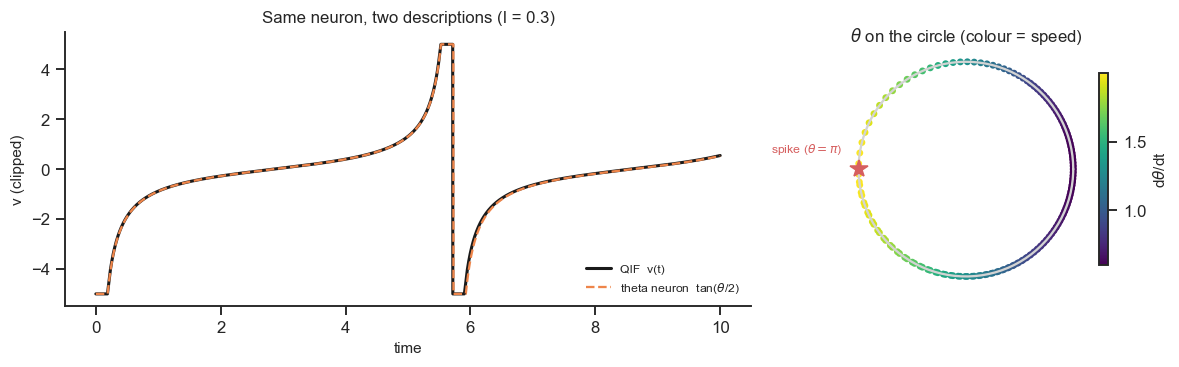

In [11]:
I0 = 0.3
T = 10
tt = np.arange(0, T, dt)
vv, spk = neurons.qif(np.full(len(tt), I0), dt, v0=-100.0)
th = neurons.theta_neuron(np.full(len(tt), I0), dt, theta0=2 * np.arctan(-100.0))

fig = plt.figure(figsize=(11, 3.5))
ax1 = fig.add_subplot(1, 3, (1, 2))
ax1.plot(tt, np.clip(vv, -5, 5), "k", lw=2, label="QIF  v(t)")
ax1.plot(tt, np.clip(np.tan(th / 2), -5, 5), "C1--", label=r"theta neuron  tan($\theta$/2)")
ax1.set(xlabel="time", ylabel="v (clipped)", title=f"Same neuron, two descriptions (I = {I0})")
ax1.legend(fontsize=8, loc="lower right")
ax2 = fig.add_subplot(1, 3, 3)
circ = np.linspace(0, 2 * np.pi, 200)
ax2.plot(np.cos(circ), np.sin(circ), c="lightgray")
speed = (1 - np.cos(th)) + (1 + np.cos(th)) * I0
sc = ax2.scatter(np.cos(th[::50]), np.sin(th[::50]), c=speed[::50], cmap="viridis", s=12)
ax2.plot(-1, 0, "r*", ms=12); ax2.text(-1.15, 0.15, r"spike ($\theta=\pi$)", color="r", fontsize=8, ha="right")
ax2.set_aspect("equal"); ax2.axis("off"); ax2.set_title(r"$\theta$ on the circle (colour = speed)")
plt.colorbar(sc, ax=ax2, shrink=0.7, label=r"d$\theta$/dt")
plt.tight_layout()

The two curves are identical. On the circle the neuron is slow near $\theta=0$ (the subthreshold
part, $v\approx 0$) and fast near $\theta=\pi$ (the spike).

## 5. The active rotator

Expand the theta neuron: $\dot\theta = (1+I) + (I-1)\cos\theta$. Shifting the angle by
$\varphi=\theta+\pi/2$ (so $\cos\theta=\sin\varphi$) gives the **active rotator** (Shinomoto & Kuramoto 1986):

$$
\boxed{\;\frac{d\varphi}{dt} = \omega + a\sin\varphi\;}
$$

with $\omega = 1+I$ and $a = I-1$. The sign of $a$ only flips the circle, so we use $a>0$ from now on.
Two parameters with a clear meaning:

* $\omega$: the natural speed of rotation (an intrinsic frequency).
* $a$: how strongly the circle is "tilted", i.e. how much the unit is pulled toward a resting position.

| | behaviour |
|---|---|
| $a<\omega$ | **oscillatory**: the unit always rotates (fires periodically) |
| $a=\omega$ | **SNIC bifurcation** |
| $a>\omega$ | **excitable**: stable rest at $\varphi^*=\pi+\arcsin(\omega/a)$, threshold at $-\arcsin(\omega/a)$ |
| $a=0$ | a pure phase oscillator: the unit of the **Kuramoto** model |

The rotation frequency is $f=\sqrt{\omega^2-a^2}/2\pi$ for $a<\omega$, and $0$ otherwise.

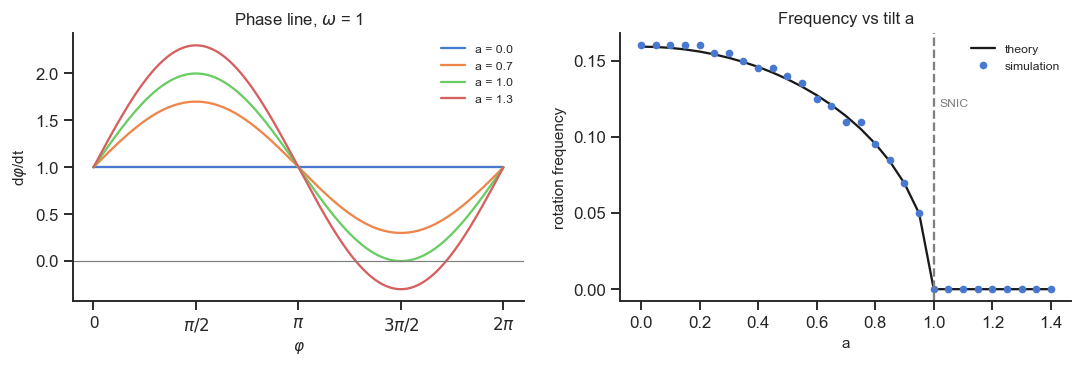

In [12]:
phi = np.linspace(0, 2 * np.pi, 400)
omega = 1.0
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a_, c in zip([0.0, 0.7, 1.0, 1.3], ["C0", "C1", "C2", "C3"]):
    ax[0].plot(phi, omega + a_ * np.sin(phi), c=c, label=f"a = {a_}")
ax[0].axhline(0, c="gray", lw=0.8)
ax[0].set(xlabel=r"$\varphi$", ylabel=r"d$\varphi$/dt", title=r"Phase line, $\omega$ = 1",
          xticks=[0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], xticklabels=["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
ax[0].legend(fontsize=8)

a_vals = np.linspace(0, 1.4, 29)
f_theory = np.sqrt(np.clip(omega**2 - a_vals**2, 0, None)) / (2 * np.pi)
f_sim = []
for a_ in a_vals:
    p = neurons.active_rotator(omega, a_, T=220, dt=1e-2)
    spikes = neurons.phase_spikes(p, 1e-2)
    f_sim.append(np.sum(spikes > 20) / 200)          # discard the first 20 time units (transient)
ax[1].plot(a_vals, f_theory, "k", label="theory")
ax[1].plot(a_vals, f_sim, "o", ms=4, label="simulation")
ax[1].axvline(omega, ls="--", c="gray"); ax[1].text(omega + 0.02, 0.12, "SNIC", color="gray", fontsize=8)
ax[1].set(xlabel="a", ylabel="rotation frequency", title="Frequency vs tilt a")
ax[1].legend(fontsize=8)
plt.tight_layout()

For $a=0.7$ the curve stays above zero: the unit rotates, slowly near $\varphi=3\pi/2$ and fast near
$\varphi=\pi/2$ (we call the fast passage a *spike*). At $a=1$ the curve touches zero at $3\pi/2$, and
for $a>1$ it crosses zero twice: a stable resting point and a threshold appear, exactly as in the QIF.
Just before the SNIC ($a\lesssim\omega$) the unit spends a long time near the "ghost" of the fixed
points, so it fires slowly.

### Explore: the active rotator

Left: phase line. Middle: $\sin\varphi(t)$ with spikes in red. Right: where the unit spends its time on the circle.
* Start with $a=0$ (Kuramoto oscillator): the unit moves at constant speed. Increase $a$: where does it slow down?
* Bring $a$ just below $\omega$ and read the period in the title. Then just above $\omega$: what happens?
* With $a>\omega$ add noise. How much noise do you need for regular-looking firing? And with $a<\omega$, what does noise do to the regularity of the clock?

In [13]:
@interact(omega=slider(1.0, 0.2, 2.0, 0.05, "omega (speed)"),
          a=slider(0.7, 0.0, 2.0, 0.01, "a (tilt)"),
          sigma=slider(0.0, 0.0, 1.0, 0.02, "noise sigma"))
def explore_rotator(omega, a, sigma):
    T, dtr = 200.0, 1e-2
    tr = np.arange(0, T, dtr)
    p = neurons.active_rotator(omega, a, T=T, dt=dtr, sigma=sigma, seed=2,
                               phi0=np.pi + np.arcsin(omega / a) if a > omega else 0.0)
    spk = neurons.phase_spikes(p, dtr)
    ph = np.linspace(0, 2 * np.pi, 300)
    fig = plt.figure(figsize=(12, 3.3))
    ax0 = fig.add_subplot(1, 4, 1)
    ax0.plot(ph, omega + a * np.sin(ph), "k"); ax0.axhline(0, c="gray", lw=0.8)
    ax0.set(xlabel=r"$\varphi$", ylabel=r"d$\varphi$/dt", title="phase line")
    ax1 = fig.add_subplot(1, 4, (2, 3))
    ax1.plot(tr, np.sin(p), "k", lw=0.6)
    for ts in spk: ax1.axvline(ts, c="C3", lw=0.6, alpha=0.6)
    isi = np.diff(spk)
    info = f"{len(spk)} spikes"
    if len(isi) > 1:
        info += f", mean ISI {isi.mean():.1f}, CV {isi.std() / isi.mean():.2f}"
    if a < omega and sigma == 0:
        info += f" (theory ISI {2 * np.pi / np.sqrt(omega**2 - a**2):.1f})"
    ax1.set(xlabel="time", ylabel=r"sin $\varphi$", ylim=(-1.2, 1.2), title=info)
    ax2 = fig.add_subplot(1, 4, 4, projection="polar")
    ax2.hist(np.mod(p, 2 * np.pi), bins=60, density=True, color="C0")
    ax2.set_yticks([]); ax2.set_title("time spent on the circle", fontsize=10)
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='omega (speed)', layout=Layo…

The **CV** (coefficient of variation of the inter-spike intervals) measures irregularity: 0 for a perfect
clock, about 1 for a random (Poisson-like) spiker. Real cortical neurons in vivo have CV close to 1.

## 6. Excitable units with noise

Real neurons receive noisy input. Add a noise term to the active rotator:

$$
\frac{d\varphi}{dt} = \omega + a\sin\varphi + \sigma\,\xi(t)
$$

where $\xi(t)$ is white noise. An *excitable* unit ($a>\omega$) does not fire on its own, but noise can
push it over the threshold from time to time.

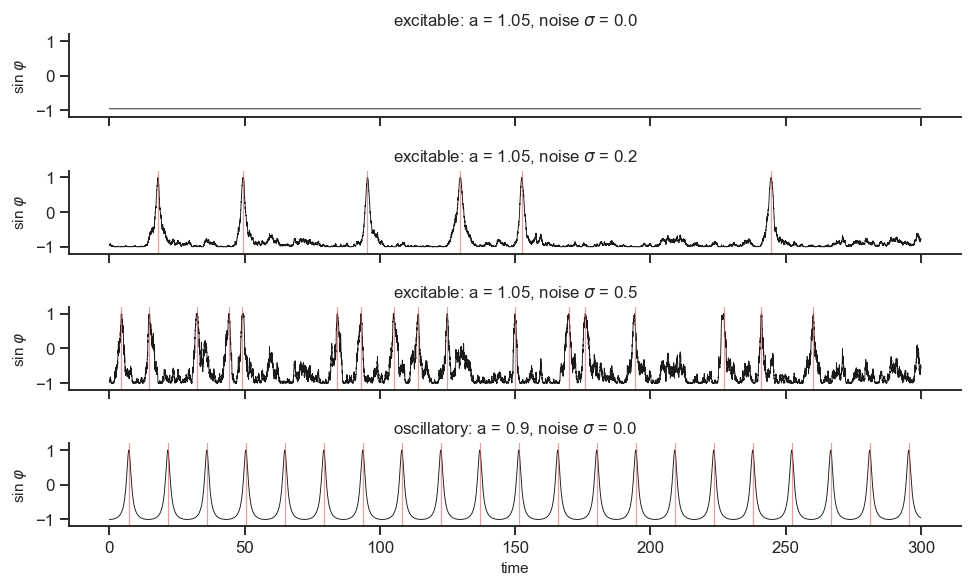

In [14]:
T, dtn = 300.0, 1e-2
tn = np.arange(0, T, dtn)
fig, ax = plt.subplots(4, 1, figsize=(9, 5.5), sharex=True)
for a_, s, row in zip([1.05, 1.05, 1.05, 0.9], [0.0, 0.2, 0.5, 0.0], ax):
    p = neurons.active_rotator(1.0, a_, T=T, dt=dtn, sigma=s, phi0=np.pi + np.arcsin(min(1, 1 / a_)), seed=1)
    row.plot(tn, np.sin(p), "k", lw=0.6)
    for ts in neurons.phase_spikes(p, dtn):
        row.axvline(ts, c="C3", lw=0.8, alpha=0.6)
    kind = "excitable" if a_ > 1 else "oscillatory"
    row.set(ylabel=r"sin $\varphi$", title=f"{kind}: a = {a_}, noise $\\sigma$ = {s}", ylim=(-1.2, 1.2))
ax[-1].set_xlabel("time")
plt.tight_layout()

* Excitable, no noise: silent.
* Excitable, weak noise: rare, irregular spikes.
* Excitable, strong noise: frequent, irregular spikes.
* Oscillatory, no noise: perfectly regular spikes.

The same unit can be a clock or a noise-driven, irregular spiker depending on two numbers ($a$ and $\sigma$).
In Chapter 4 we will see that thousands of such units coupled together produce very different
**collective** regimes (asynchronous, synchronous, critical) depending on exactly these parameters.

## 7. Take-home

* One variable keeps the essentials of excitability: threshold (an unstable fixed point), all-or-none
  spikes, repetitive firing above a bifurcation.
* QIF, theta neuron and active rotator are the **same dynamics** in different coordinates; the
  Kuramoto oscillator is the special case $a=0$.
* What we lost: ion channels, spike shape, the exact biophysical meaning of the parameters.
  What we gained: analytic results (threshold, f–I curve, bifurcation), and a unit cheap enough to
  simulate **thousands** of times. That is the next chapter.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. For the QIF at $I=-1$, show analytically that a pulse of duration 0.1 needs an amplitude of about 20 to cause a spike. Compare with the simulation in section 2.
2. Simulate the theta neuron with $I=-0.2$. Where does it come to rest on the circle? Relate it to $v_\text{rest}=-\sqrt{0.2}$.
3. Plot the firing rate of the excitable rotator ($a=1.05$, $\omega=1$) as a function of $\sigma$ between 0 and 1 (use `neurons.active_rotator` and `neurons.phase_spikes`).
4. For the same unit, plot the CV of the inter-spike intervals as a function of $\sigma$. Is there a noise level where firing is *most regular*? (This is called *coherence resonance*.)

### References
* Hodgkin AL (1948). The local electric changes associated with repetitive action in a non-medullated axon. *J Physiol* 107:165–181.
* Ermentrout GB, Kopell N (1986). Parabolic bursting in an excitable system coupled with a slow oscillation. *SIAM J Appl Math* 46:233–253.
* Ermentrout B (1996). Type I membranes, phase resetting curves, and synchrony. *Neural Comput* 8:979–1001.
* Shinomoto S, Kuramoto Y (1986). Phase transitions in active rotator systems. *Prog Theor Phys* 75:1105–1110.
* Izhikevich EM (2007). *Dynamical Systems in Neuroscience*, ch. 3, 4 and 7 (the $I_\text{Na,p}+I_\text{K}$ model, nullclines, normal forms). MIT Press.
* Gerstner W et al. (2014). *Neuronal Dynamics*, ch. 5 (free online).